# Referable diabetic retinopathy triage on APTOS 2019

This notebook trains and evaluates the model behind the Sentient screening app. It covers every stage from the problem to deployment; the table below shows where each stage sits. Technical terms are explained in the glossary after this section.

## 0. Problem and approach

**Problem.** Diabetic retinopathy (DR) damages the retina and is a leading cause of preventable blindness. Screening with retinal photographs catches it early, but each photograph must be graded, and Kenya has few eye specialists. At Kenyatta National Hospital, adding on-site retinal photography and grading to the diabetes clinic raised referrals to the eye clinic from 494 to 1,065 in six months, and sight-saving treatments from 107 to 333 (Gichuhi et al., 2017). The grading step is what this project supports.

**Question.** To what extent can an AI-based triage tool accurately flag referable DR in existing fundus photographs? *Referable* means ICDR grade 2 (moderate) or worse: the level at which a patient should see an eye specialist.

**Success criteria, fixed before the test set was opened** (proposal, Section 3.12.1):
- **H1.** On the held-out test images, the app's model reaches a sensitivity of at least 0.90 with a specificity of at least 0.70.
- **H2.** It beats the simple baselines (a majority-class predictor and a small CNN trained from scratch), and the small MobileNetV2 is not worse than the larger EfficientNetB0 in AUC.
- **H3.** The deployed model gives the same results as this notebook. This is checked outside the notebook (section 13).

Sensitivity is the primary measure: a missed referable eye can cost sight, while a false alarm costs one specialist visit.

**Data.** APTOS 2019 Blindness Detection: 3,662 colour fundus photographs from Aravind Eye Hospital, India, each graded 0 to 4 by clinicians. The images are not in the repository; download them from the Kaggle competition page and set `DATA_DIR` in section 1.

**Approach.** The five grades become one yes/no target (referable or not). Duplicate and conflicting images are removed, a third of the images is locked away for testing, and three networks are trained with 5-fold cross-validation. The decision threshold is chosen on validation images for at least 90% sensitivity. One fold model of the chosen network goes into the app.

| Data mining stage (CRISP-DM) | Sections |
| --- | --- |
| Business understanding | 0. Problem and approach |
| Data understanding | 2. Exploratory data analysis |
| Data preparation | 3. Data cleaning; 4. Train, validation and test split; 5. Image array |
| Modelling | 6. Model 1: EfficientNetB0 (base model); 7. Comparison models |
| Evaluation | 8. Statistical comparison; 9. The single model for the app, with results by grade; 10. Explainability; 12. Summary and limitations |
| Deployment | 11. Export to TensorFlow Lite; 13. Deployment |

**Running it.** Written for Google Colab with the dataset in Google Drive. Long steps (image metrics, the image array, every trained fold) are saved to Drive, so a rerun resumes instead of starting over. Figures that show APTOS photographs were removed from this copy (see the notes in those cells); every number and chart remains.

### Glossary

| Term | Meaning here |
| --- | --- |
| Referable DR | ICDR grade 2 (moderate) or worse. The positive class. Grades 0 (no DR) and 1 (mild) are non-referable. |
| Sensitivity | Of the eyes that are referable, the share the model flags. A sensitivity of 0.905 means 400 of 442 referable test eyes were flagged. |
| Specificity | Of the eyes that are not referable, the share the model leaves unflagged. |
| Threshold | The probability above which an eye is flagged. Chosen on validation images, here 0.793, because the usual 0.5 gives a lower sensitivity. |
| ROC curve, AUC | The ROC curve plots sensitivity against the false-alarm rate for every possible threshold. AUC (area under that curve) summarises it: 0.5 is guessing, 1.0 is perfect. |
| Accuracy | The share of all eyes classified correctly. Misleading on imbalanced data: always answering "not referable" scores 0.62 here. |
| Majority-class baseline | A "model" that always predicts the most common class. Anything useful must beat it. |
| Data leakage | Information from test images reaching training, for example the same photograph on both sides. It makes results look better than they are. |
| MD5, pHash | Two fingerprints of an image. MD5 matches identical files; a perceptual hash (pHash) also matches images that look the same after resizing or re-saving. Used to find duplicates. |
| Stratified, grouped split | Each part keeps the same share of referable images (stratified), and images with the same pHash stay together (grouped), so no photograph is in both training and test. |
| Cross-validation, fold | The development images are cut into 5 parts (folds). Each model trains on 4 and is validated on the 5th, five times over. |
| Transfer learning | Starting from a network already trained on ImageNet (1.2 million everyday photographs) and fine-tuning it on retinal images, instead of training from zero. |
| CNN | Convolutional neural network: the standard network type for images. EfficientNetB0 and MobileNetV2 are CNNs designed by others; the "simple CNN" is a small one built here. |
| Data augmentation | Random flips, rotations, zoom and contrast changes applied to training images, so the network does not memorise exact pictures. |
| Class weights | Errors on the rarer class count more during training, so the network does not ignore it. |
| Dropout | Randomly switching off part of the network during training, which reduces overfitting. |
| Early stopping | Stopping training when validation AUC stops improving, and keeping the best epoch. |
| Batch normalisation | A layer that rescales values inside the network. Its running averages caused the MobileNetV2 problem fixed in section 7. |
| Ensemble | The average prediction of the 5 fold models. Used to compare architectures; the app uses one fold model. |
| Bootstrap confidence interval | Resampling the test images 2,000 times with replacement and recomputing a measure each time. The middle 95% of the results is the interval. |
| Paired bootstrap | The same, but scoring two models on the same resampled images, which gives an interval for their difference. |
| McNemar test | A test of whether two models make different mistakes on the same images. |
| Bonferroni correction | Dividing the significance level by the number of tests (0.05 / 3), so running several tests does not inflate false findings. |
| Wilson interval | A confidence interval for a proportion such as sensitivity that stays sensible for small counts. |
| Class activation map (CAM) | A heat map of which image regions raised the referral score. It shows where the model found evidence; it is not a diagnosis. |
| TensorFlow Lite, quantisation | A compact model format for phones. Quantisation stores weights as 8-bit integers, which makes the file smaller but can change results slightly. |

## 1. Setup
The next cells mount Google Drive, load the label table, and define helpers that give a fast local copy of the images only when the raw images are really needed (the first run). Reading thousands of small files from Drive is slow, so the local copy is used for any heavy image work.

In [ ]:
import os
import pandas as pd
import kagglehub

# Mount Google Drive first so that the mount point is created securely
from google.colab import drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# Define global DATA_DIR safely after mounting
DATA_DIR = '/content/drive/MyDrive/APTOS2019_Data'
os.makedirs(DATA_DIR, exist_ok=True)

# Check if dataset is already present in Google Drive to avoid redundant downloads
csv_file_path = os.path.join(DATA_DIR, 'train.csv')

if os.path.exists(csv_file_path):
    print("Dataset already exists in Google Drive. Skipping download.")
    path = DATA_DIR
    df = pd.read_csv(csv_file_path)
else:
    print("Dataset not found in Google Drive. Downloading...")
    path = kagglehub.competition_download('aptos2019-blindness-detection')
    temp_csv_file_path = os.path.join(path, 'train.csv')
    if os.path.exists(temp_csv_file_path):
        df = pd.read_csv(temp_csv_file_path)
    else:
        print(f"Error: '{temp_csv_file_path}' not found. Please check download.")

Mounting Google Drive...
Mounted at /content/drive
Dataset already exists in Google Drive. Skipping download.


In [ ]:
import shutil
import os

# Define source and destination paths
source_dir = path # Current kagglehub download directory
dest_dir = '/content/drive/MyDrive/APTOS2019_Data'

# Check if files already exist in destination to avoid repeating copying process
if source_dir == dest_dir:
    print("Dataset is already in Google Drive destination folder.")
else:
    print(f"Copying dataset files from temporary cache to Google Drive folder: '{dest_dir}'")
    print("This may take a few minutes depending on your Drive write speed...")

    # Copy each item in the directory to avoid nested duplicate folders
    for item in os.listdir(source_dir):
        s_item = os.path.join(source_dir, item)
        d_item = os.path.join(dest_dir, item)
        if os.path.isdir(s_item):
            if not os.path.exists(d_item):
                shutil.copytree(s_item, d_item)
                print(f"Copied directory: {item}")
        else:
            if not os.path.exists(d_item):
                shutil.copy2(s_item, d_item)
                print(f"Copied file: {item}")

    print("\nDone! Your dataset is now permanently stored in your Google Drive.")

In [ ]:
import os, json, time, hashlib, shutil, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
warnings.filterwarnings('ignore')

LOCAL_DATA_DIR = '/content/APTOS2019_Data_Local'
DRIVE_IMG_DIR = os.path.join(DATA_DIR, 'train_images')
N_RAW = 3662

def _complete(folder):
    return os.path.isdir(folder) and len(os.listdir(folder)) >= N_RAW

def ensure_local_images():
    """Return a fast local folder with all training images. Downloads from Kaggle on the first call."""
    local_dir = os.path.join(LOCAL_DATA_DIR, 'train_images')
    if _complete(local_dir):
        return local_dir
    import kagglehub
    kagglehub.login()
    source = kagglehub.competition_download('aptos2019-blindness-detection')
    os.makedirs(LOCAL_DATA_DIR, exist_ok=True)
    print('Copying training images to local disk ...')
    shutil.copytree(os.path.join(source, 'train_images'), local_dir, dirs_exist_ok=True)
    return local_dir

def image_dir():
    """Local copy when present (fast), otherwise the Drive copy (slow, fine for a few images)."""
    local_dir = os.path.join(LOCAL_DATA_DIR, 'train_images')
    return local_dir if _complete(local_dir) else DRIVE_IMG_DIR

def set_image_paths(frame, folder=None):
    folder = folder or image_dir()
    frame['image_path'] = frame['id_code'].apply(lambda x: os.path.join(folder, f'{x}.png'))
    return frame

df = set_image_paths(df)
print('Images are read from:', image_dir())

## 2. Exploratory data analysis
Cells here check the size and completeness of the label table, the class balance, the referral definition, and image quality (resolution, brightness, sharpness, black borders). Image-level metrics and two hashes per image are computed once and saved to Drive: an **MD5** hash of the pixel data (finds exact duplicates) and a **pHash** (finds visually near-identical images). Duplicates matter because copies of one photograph on both sides of a split would inflate the test score.

In [ ]:
#How many rows and columns are in the dataset
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")
#Looking for null values
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("The dataset is complete with no missing values.")
else:
    print("Missing values in each column:")
    display(missing_values[missing_values > 0])

#duplicate id_code values
duplicate_count = df['id_code'].duplicated().sum()
print(f"The dataset has {duplicate_count} duplicate images")

The dataset has 3662 rows and 3 columns.
The dataset is complete with no missing values.
The dataset has 0 duplicate images


In [ ]:
# Returns a Series showing each value and its frequency
print(df["diagnosis"].value_counts())

diagnosis
0    1805
2     999
1     370
4     295
3     193
Name: count, dtype: int64


### Clinical Referral Guidelines

- **Non-referable:** Grades 0 and 1
- **Referable:** Grades 2, 3, and 4 (since Grade 2 indicates moderate diabetic retinopathy which warrants clinical monitoring)

In [ ]:
METRIC_COLS = ['width', 'height', 'file_size_kb', 'mean_brightness', 'sharpness_score', 'black_pixel_share']
HASH_COLS = ['md5', 'phash']
ENRICHED = os.path.join(DATA_DIR, 'enriched_train_metrics.csv')

def extract_image_metrics(path):
    metrics = {c: np.nan for c in METRIC_COLS}
    if not isinstance(path, str) or not os.path.exists(path):
        return metrics
    try:
        metrics['file_size_kb'] = os.path.getsize(path) / 1024
        img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img_gray is None:
            return metrics
        metrics['height'], metrics['width'] = img_gray.shape
        metrics['mean_brightness'] = np.mean(img_gray)
        metrics['sharpness_score'] = cv2.Laplacian(img_gray, cv2.CV_64F).var()
        metrics['black_pixel_share'] = np.sum(img_gray == 0) / img_gray.size
    except Exception:
        pass
    return metrics

cached = pd.read_csv(ENRICHED) if os.path.exists(ENRICHED) else None
if cached is not None and len(cached) == len(df) and all(c in cached.columns for c in METRIC_COLS + HASH_COLS):
    print('Loaded image metrics and hashes saved earlier.')
    df = df[['id_code', 'diagnosis']].merge(cached[['id_code'] + METRIC_COLS + HASH_COLS], on='id_code', how='left')
    df = set_image_paths(df)
else:
    df = set_image_paths(df, ensure_local_images())
    print('Processing image metrics (a few minutes) ...')
    tqdm.pandas(desc='Extracting metrics')
    metrics_df = pd.DataFrame(df['image_path'].progress_apply(extract_image_metrics).tolist())
    df = df.drop(columns=[c for c in metrics_df.columns if c in df.columns])
    df = pd.concat([df, metrics_df], axis=1)
    print('Metrics calculation complete.')

def plot_extreme_images(dataframe, metric_col, title, ascending=True, num_images=5):
    valid_df = dataframe.dropna(subset=[metric_col, 'image_path'])
    sorted_df = valid_df.sort_values(by=metric_col, ascending=ascending).head(num_images)
    fig, axes = plt.subplots(1, num_images, figsize=(18, 5))
    fig.suptitle(title, fontsize=16, fontweight='bold')
    for i, (_, row) in enumerate(sorted_df.iterrows()):
        ax = axes[i]
        img = cv2.imread(row['image_path'])
        if img is not None:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.text(0.5, 0.5, 'Failed to load', ha='center', va='center')
        ax.set_title(f"ID: {row['id_code']}\n{metric_col.replace('_', ' ').title()}: {row[metric_col]:.2f}\nDiagnosis: {row['diagnosis']}", fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

plot_extreme_images(df, 'mean_brightness', 'Top 5 darkest images', ascending=True)
plot_extreme_images(df, 'sharpness_score', 'Top 5 blurriest images', ascending=True)
plot_extreme_images(df, 'mean_brightness', 'Top 5 brightest / overexposed images', ascending=False)

Loaded image metrics and hashes saved earlier.


[Figures removed from the repository copy: they show the darkest, blurriest and brightest images in the dataset. They are APTOS 2019
photographs, which the competition rules do not allow us to redistribute. Run this cell
with the dataset in place to see them.]


In [ ]:
!pip install -q imagehash

In [ ]:
import hashlib
from PIL import Image
import imagehash

def compute_hashes(image_path):
    try:
        if not os.path.exists(image_path):
            return None, None
        with Image.open(image_path) as img:
            md5_hash = hashlib.md5(img.tobytes()).hexdigest()   # exact duplicate check
            phash_val = str(imagehash.phash(img))               # near-duplicate check
        return md5_hash, phash_val
    except Exception:
        return None, None

if 'md5' not in df.columns or df['md5'].isna().any():
    df = set_image_paths(df, ensure_local_images())
    tqdm.pandas(desc='Hashing images')
    hashes = df['image_path'].progress_apply(compute_hashes)
    df['md5'] = [h[0] for h in hashes]
    df['phash'] = [h[1] for h in hashes]
else:
    print('Hashes already available.')

exact_duplicates = df[df.duplicated(subset=['md5'], keep=False) & df['md5'].notna()]
print(f"Found {exact_duplicates['md5'].nunique()} groups of exact duplicate files (totaling {len(exact_duplicates)} images).")

near_duplicates = df[df.duplicated(subset=['phash'], keep=False) & df['phash'].notna()]
print(f"Found {near_duplicates['phash'].nunique()} groups of visually identical/near-duplicate files (totaling {len(near_duplicates)} images).")

conflicting_labels = df.groupby('phash').filter(lambda x: x['diagnosis'].nunique() > 1)
if not conflicting_labels.empty:
    print(f"\nDetected {conflicting_labels['phash'].nunique()} cases where visually near-identical images have conflicting diagnosis labels.")
    display(conflicting_labels[['id_code', 'diagnosis', 'phash']].sort_values(by='phash').head(10))
else:
    print('\nNo conflicting diagnosis labels found among the near-duplicate images.')

Hashes already available.
Found 123 groups of exact duplicate files (totaling 251 images).
Found 143 groups of visually identical/near-duplicate files (totaling 295 images).

Detected 38 cases where visually near-identical images have conflicting diagnosis labels.


,id_code,diagnosis,phash
297,1632c4311fc9,2,808d0f3513f33f2d
2388,a75bab2463d4,1,808d0f3513f33f2d
1847,8273fdb4405e,1,808d17715f871ff0
3453,f0098e9d4aee,4,808d17715f871ff0
3462,f066db7a2efe,0,8181179d1fe15b9d
557,278aa860dffd,1,8181179d1fe15b9d
1876,8446826853d0,2,85685fa13eb45a63
2035,8ef2eb8c51c4,1,85685fa13eb45a63
2194,9a3c03a5ad0f,2,85855ed62ead5a52
3460,f03d3c4ce7fb,4,85855ed62ead5a52


### Exploratory Data Analysis & Quality Assessment Observations

1. **Imbalance in severity classes:** Non-referable cases (especially Grade 0: 1,805 samples) in the raw data make up the majority of the dataset. Therefore, relying solely on standard accuracy will yield misleading performance metrics. We balance this by introducing class weights during training and evaluating models with sensitivity/specificity.

2. **High variation in resolution and aspect ratio:** The raw retinal images exhibit highly diverse dimensions (e.g., 3216×2136, 2416×1736, 1050×1050). The resizing process alters these aspect ratios to a uniform 224×224, which is documented below under limitations.

3. **Illumination and clarity issues:** The dataset features vast ranges in image qualities. To analyze this variation objectively, the top extreme samples were compiled:

| ID | Type | Mean Brightness | Sharpness Score | Diagnosis |
|---|---|---|---|---|
| d4583e9525dc | Darkest | 14.73 | 6.86 | 0 |
| 87d461bcc4e9 | Darkest | 16.34 | 4.09 | 0 |
| ccd6dcb2f568 | Darkest | 16.40 | 10.20 | 0 |
| 436fa3fd145a | Darkest | 16.91 | 43.88 | 0 |
| 7269a1d84a57 | Darkest | 16.93 | 27.99 | 0 |
| 6a244e855d0e | Blurriest | 52.12 | 3.07 | 3 |
| a3bd2e034614 | Blurriest | 25.14 | 3.15 | 0 |
| 1f543e86c4d4 | Blurriest | 48.91 | 3.27 | 2 |
| ca9c912ebad7 | Blurriest | 55.20 | 3.30 | 2 |
| 1c0e5dd1b14c | Blurriest | 59.88 | 3.32 | 2 |

*Note: Color and temperature variations may likely originate from varying imaging hardware models used across clinics (camera models are undocumented hypothetical sources of shift).*

4. **Duplications and visual overlaps:** 123 groups of exact binary replicates (MD5) and 143 visually near-identical duplicate groups (pHash) were found. If separated across splits, these could falsely inflate evaluation performance. Visually near-identical images with conflicting diagnoses (38 cases) were discarded to preserve labeling consistency.

5. **Grouping classes to clinical objectives:** Standardizing labels into clinical referral status (Referable vs. Non-referable) drastically improves group balance (about 38.8% referable and 61.2% non-referable after cleaning) and aligns directly with the core application objective.

In [ ]:
# Save the enriched DataFrame containing all metrics, MD5, and pHash values to Google Drive
saved_csv_path = '/content/drive/MyDrive/APTOS2019_Data/enriched_train_metrics.csv'

try:
    df.to_csv(saved_csv_path, index=False)
    print(f"Successfully saved the enriched dataset with all calculated properties and hashes to: {saved_csv_path}")
except NameError:
    print("Error: 'df' DataFrame is not defined in the current session. Please make sure to run the metric and hash extraction cells first.")
except Exception as e:
    print(f"An error occurred while saving: {e}")

Successfully saved the enriched dataset with all calculated properties and hashes to: /content/drive/MyDrive/APTOS2019_Data/enriched_train_metrics.csv


## 3. Data cleaning
Order of operations: (1) remove every exact-duplicate group whose copies carry different labels (the label cannot be trusted), (2) keep one copy of each remaining exact-duplicate group, (3) remove every near-duplicate group (same pHash) whose members carry different labels. The cleaned table is saved to Drive. Then the preprocessing functions are defined: crop the black border, resize to 224x224.

In [ ]:
# 1. Identify exact duplicate groups (MD5) containing conflicting labels
conflict_md5_groups = df.groupby('md5').filter(lambda x: x['diagnosis'].nunique() > 1)
conflict_md5s = conflict_md5_groups['md5'].unique()
print(f"Found {len(conflict_md5s)} MD5 groups with conflicting labels. Dropping all of them.")

df_cleaned = df[~df['md5'].isin(conflict_md5s)].copy()

# Drop exact duplicates, keeping the first occurrence
before_exact = len(df_cleaned)
df_cleaned = df_cleaned.drop_duplicates(subset=['md5'], keep='first')
print(f"Retained first occurrences. Count dropped from {before_exact} to {len(df_cleaned)}.")

# 2. Identify near-duplicates (pHash) with conflicting labels
conflicting_phash_groups = df_cleaned.groupby('phash').filter(lambda x: x['diagnosis'].nunique() > 1)
conflicting_phashes = conflicting_phash_groups['phash'].unique()
print(f"Found {len(conflicting_phashes)} pHash groups with conflicting labels. Dropping all of them.")

df_cleaned = df_cleaned[~df_cleaned['phash'].isin(conflicting_phashes)]

cleaned_csv_path = os.path.join(DATA_DIR, 'cleaned_train_metrics.csv')
df_cleaned.to_csv(cleaned_csv_path, index=False)
print(f"Final clean count: {len(df_cleaned)}. Saved to {cleaned_csv_path}")

Found 30 MD5 groups with conflicting labels. Dropping all of them.
Retained first occurrences. Count dropped from 3600 to 3504.
Found 8 pHash groups with conflicting labels. Dropping all of them.
Final clean count: 3487. Saved to /content/drive/MyDrive/APTOS2019_Data/cleaned_train_metrics.csv


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def crop_black_border(img, tol=7):
    """
    Crops out the black border around the retinal circle.
    """
    if img.ndim == 2:
        mask = img > tol
        return img[np.ix_(mask.any(1), mask.any(0))]
    elif img.ndim == 3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        mask = gray_img > tol

        check_shape = img[:,:,0][np.ix_(mask.any(1), mask.any(0))].shape[0]
        if check_shape == 0:
            return img # Return original image if it is too dark or empty
        else:
            img1 = img[:,:,0][np.ix_(mask.any(1), mask.any(0))]
            img2 = img[:,:,1][np.ix_(mask.any(1), mask.any(0))]
            img3 = img[:,:,2][np.ix_(mask.any(1), mask.any(0))]
            img = np.stack([img1, img2, img3], axis=-1)
        return img

def preprocess_image(image_path, target_size=224, enhance_lesions=False):
    """
    Loads, crops, resizes, and processes a single image.
    Optionally subtracts the local average color using Gaussian blur.
    """
    img = cv2.imread(image_path)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 1. Crop black border
    img = crop_black_border(img)

    # 2. Resize to target size (224x224)
    img = cv2.resize(img, (target_size, target_size))

    # 3. Apply optional local average subtraction (Graham's method)
    if enhance_lesions:
        # Gaussian blur with a sigma proportional to the target size
        img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), target_size / 30), -4, 128)

    return img

# Note: the models take raw 0-255 pixels. EfficientNetB0 normalises inside the network and the
# MobileNetV2 model rescales inside its own input layer, so no external normalisation is applied.

# Let's visualize the pipeline with a few sample images
sample_rows = df_cleaned.sample(2, random_state=42)

for idx, row in sample_rows.iterrows():
    img_path = row['image_path']

    # Get original raw image
    raw_img = cv2.imread(img_path)
    raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)

    # Standard Preprocessed (Cropped + Resized to 224)
    std_img = preprocess_image(img_path, target_size=224, enhance_lesions=False)

    # Enhanced Preprocessed (Cropped + Resized + Local Color Subtraction)
    enhanced_img = preprocess_image(img_path, target_size=224, enhance_lesions=True)

    # Plot side-by-side comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"Preprocessing Pipeline for ID: {row['id_code']} (Diagnosis: {row['diagnosis']})", fontsize=14, fontweight='bold')

    axes[0].imshow(raw_img)
    axes[0].set_title("Original Raw Image")
    axes[0].axis('off')

    axes[1].imshow(std_img)
    axes[1].set_title("Standard Resized (224x224)")
    axes[1].axis('off')

    axes[2].imshow(enhanced_img)
    axes[2].set_title("Enhanced (Local Color Subtraction)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

[Figures removed from the repository copy: they show two images before and after preprocessing. They are APTOS 2019
photographs, which the competition rules do not allow us to redistribute. Run this cell
with the dataset in place to see them.]


### Cleaning summary

| Step | Images remaining |
|---|---|
| Raw training images | 3,662 |
| After removing 30 exact-duplicate groups with conflicting labels (62 images) | 3,600 |
| After keeping one copy of each remaining exact-duplicate group | 3,504 |
| After removing 8 near-duplicate groups with conflicting labels (17 images) | 3,487 |

Final: 3,487 images, of which 2,133 are non-referable and 1,354 referable. Cropping removes the uninformative black border and every image is resized to 224x224. Resizing does not keep the aspect ratio, which is listed under limitations.

## 4. Train, validation and test split
One third of the images is set aside as a locked **test set**. It plays no part in training, in choosing thresholds or in choosing the fold model for the app. It is used for the final evaluation, and also for the comparison of architectures in section 8, under a decision rule written before that comparison was run (section 7). Because the same test set informs the choice of architecture and reports its performance, the reported figures may be slightly optimistic. The remaining two thirds (development data) are divided into 5 folds for cross-validation. The split is stratified on the referable label and **grouped by pHash**, so copies of the same photograph always stay on the same side. Two checks print the number of shared pHash values between development and test, and between validation folds and their training folds. Both must be 0.

The test set is one third of the data (about 67/33). Test results therefore have a narrower confidence interval than they would with a smaller test set.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
import os

# 1. Label the eyes: 0 = no referral, 1 = referral needed

df_cleaned['referable'] = (df_cleaned['diagnosis'] >= 2).astype(int)

labels = df_cleaned['referable']
image_groups = df_cleaned['phash']

# 2. Start by marking all images as development data
df_cleaned['split'] = 'dev'
df_cleaned['cv_fold'] = -1

# 3. Separate one third of the images for final testing (3 groups, the first group becomes the test set)
splitter = StratifiedGroupKFold(
    n_splits=(3), shuffle=True, random_state=42
)

train_rows, test_rows = next(
    splitter.split(df_cleaned, labels, groups=image_groups)
)

# Mark the selected images as test data
df_cleaned.iloc[test_rows, df_cleaned.columns.get_loc('split')] = 'test'

# 4. Divide the remaining images into 5 validation groups
train_data = df_cleaned.iloc[train_rows].copy()

five_folds = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

for fold, (_, validation_rows) in enumerate(
    five_folds.split(
        train_data,
        train_data['referable'],
        groups=train_data['phash']
    ),
    start=1
):
    # Give each validation image its fold number (1 to 5)
    image_ids = train_data.index[validation_rows]
    df_cleaned.loc[image_ids, 'cv_fold'] = fold

# 5. Check that matching images aren't shared between development and test
dev_hashes = set(df_cleaned.loc[df_cleaned['split'] == 'dev', 'phash'])
test_hashes = set(df_cleaned.loc[df_cleaned['split'] == 'test', 'phash'])

print("Matching images between development and test:",
      len(dev_hashes & test_hashes))

# Check that matching images aren't shared between validation folds
leaks = 0

for fold in range(1, 6):
    validation_hashes = set(df_cleaned.loc[df_cleaned['cv_fold'] == fold, 'phash'])
    training_hashes = set(df_cleaned.loc[
        (df_cleaned['split'] == 'dev') & (df_cleaned['cv_fold'] != fold),
        'phash'
    ])
    leaks += len(validation_hashes & training_hashes)

print("Matching images across validation folds:", leaks)

# 6. Save the dataset
df_cleaned.to_csv(os.path.join(DATA_DIR, 'split_dataset.csv'), index=False)
print("Dataset saved!")

share = (df_cleaned['split'] == 'test').mean()
print(f"Test share: {share:.1%} ({(df_cleaned['split'] == 'test').sum()} images), development share: {1 - share:.1%}")

Matching images between development and test: 0
Matching images across validation folds: 0
Dataset saved!
Test share: 33.3% (1162 images), development share: 66.7%


In [ ]:
# Load the dataset we saved in the previous cell
data = pd.read_csv(os.path.join(DATA_DIR, 'split_dataset.csv'))
########
# Show how many images are in each split and fold
print("Images in each group:")
print(data.groupby(['split', 'cv_fold']).size())

# Show how many images need referral (1) or don't (0)
print("\nImages by referral category:")
print(data.groupby(['split', 'referable']).size())

Images in each group:
split  cv_fold
dev     1          463
        2          466
        3          464
        4          468
        5          464
test   -1         1162
dtype: int64

Images by referral category:
split  referable
dev    0            1413
       1             912
test   0             720
       1             442
dtype: int64


In [ ]:
# Check where our dataset is stored in Google Drive
print("Dataset folder:", DATA_DIR)

# Show the files inside the folder
print("Files:", os.listdir(DATA_DIR))

Dataset folder: /content/drive/MyDrive/APTOS2019_Data
Files: ['sample_submission.csv', 'test.csv', 'train.csv', 'train_images', 'test_images', 'train_split.csv', 'val_split.csv', 'test_split.csv', 'X_224.npy', 'Task3_results', 'Task4_results', 'enriched_train_metrics.csv', 'cleaned_train_metrics.csv', 'split_dataset.csv', 'y.npy', 'id_codes.npy', 'groups.npy', 'gradcam_heatmap_A_Conflicting_Unseen.png', 'gradcam_heatmap_B_Missed_Referable_FN.png', 'gradcam_heatmap_C_Correct_Referable_TP.png']


In [ ]:
# Open the cleaned dataset we saved earlier
df_cleaned = pd.read_csv(DATA_DIR + '/split_dataset.csv')

# Create the full file location for each eye photograph
df_cleaned = set_image_paths(df_cleaned)

# Show the number of rows and columns
print("Dataset size:", df_cleaned.shape)

Dataset size: (3487, 14)


In [ ]:
# Convert the 5 disease grades into 2 categories
# 0 = No referral needed (grades 0 and 1)
# 1 = Referral needed (grades 2, 3 and 4)
df_cleaned['referable'] = (df_cleaned['diagnosis'] >= 2).astype(int)

# Count how many images belong to each category
print(df_cleaned['referable'].value_counts())

referable
0    2133
1    1354
Name: count, dtype: int64


## 5. Image array
Every cleaned image is cropped, resized to 224x224 and stacked into one array (`X_224.npy`) so that training reads one file from memory instead of thousands of image files. The array is cached on Drive. The cache is only reused when its image IDs match the current table row for row.

In [ ]:
from concurrent.futures import ThreadPoolExecutor

y = df_cleaned['referable'].values
groups = df_cleaned['phash'].values
id_codes = df_cleaned['id_code'].values

X_PATH = os.path.join(DATA_DIR, 'X_224.npy')
IDS_PATH = os.path.join(DATA_DIR, 'id_codes.npy')

def cache_matches():
    if not (os.path.exists(X_PATH) and os.path.exists(IDS_PATH)):
        return False
    saved_ids = np.load(IDS_PATH, allow_pickle=True)
    return len(saved_ids) == len(id_codes) and bool((saved_ids == id_codes).all())

if cache_matches():
    X = np.load(X_PATH)
    print('Loaded cached image array:', X.shape)
else:
    local_df = set_image_paths(df_cleaned.copy(), ensure_local_images())
    paths = local_df['image_path'].tolist()
    with ThreadPoolExecutor(max_workers=16) as pool:
        images = list(tqdm(pool.map(lambda p: preprocess_image(p, target_size=224), paths), total=len(paths)))
    X = np.stack(images).astype(np.uint8)
    np.save(X_PATH, X); np.save(IDS_PATH, id_codes)
    np.save(os.path.join(DATA_DIR, 'y.npy'), y); np.save(os.path.join(DATA_DIR, 'groups.npy'), groups)
    print('Images loaded and saved. Shape:', X.shape)

assert len(X) == len(y) == len(groups) == len(id_codes) == len(df_cleaned)

dev_mask = (df_cleaned['split'] == 'dev').values
test_mask = (df_cleaned['split'] == 'test').values
X_dev, y_dev, g_dev = X[dev_mask], y[dev_mask], groups[dev_mask]
X_test, y_test = X[test_mask], y[test_mask]
print(f'Development: {len(y_dev)} images ({y_dev.mean():.1%} referable) | Test: {len(y_test)} images ({y_test.mean():.1%} referable)')

Loaded cached image array: (3487, 224, 224, 3)
Development: 2325 images (39.2% referable) | Test: 1162 images (38.0% referable)


In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print(gpus)
if not gpus:
    print('WARNING: no GPU found. Training will be about 20 times slower. Runtime, Change runtime type, T4 GPU.')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 6. Model 1: EfficientNetB0 (base model)
**Model.** EfficientNetB0 pretrained on ImageNet (transfer learning), with its classification layer replaced by dropout (0.3) and one sigmoid output that gives the probability that the eye is referable. Random flips, rotation, zoom and contrast are applied only during training.

**Validity measures.** 5-fold cross-validation on the development data, class weights for the class imbalance, dropout, early stopping on validation AUC (patience 4), learning-rate reduction when validation loss stalls, and a locked test set.

**Threshold.** For each fold the decision threshold is chosen on the validation images as the one that reaches at least 90% sensitivity with the fewest false alarms. The same threshold is then applied to the test images. Missing a referable eye costs more than a false alarm, hence the sensitivity target.

**Final prediction.** Average of the 5 fold models, with the average of their thresholds.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# 1. Make training photos slightly different each time
# This helps the AI recognize eyes in different conditions
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
], name='augment')


# 2. Create our EfficientNetB0 model
def build_model(lr=0.0001):

    # Load EfficientNetB0 with knowledge from ImageNet
    # Remove its original classification layer
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3),
        pooling='avg'
    )

    # Our model receives 224 x 224 colour eye photographs
    inputs = keras.Input((224, 224, 3))

    # Randomly change photos during training
    x = augment(inputs)

    # Let EfficientNetB0 examine the image features
    x = base(x)

    # Reduce the chance of memorizing training images
    x = layers.Dropout(0.3)(x)

    # Give a score between 0 and 1 for referral
    outputs = layers.Dense(1, activation='sigmoid')(x)

    # Connect everything into one model
    model = keras.Model(inputs, outputs)

    # Set up how the model learns and how we measure it
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc')]
    )

    return model


# 3. Display the model's structure
build_model().summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 4,008,829 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# 1. Find the best cut-off for deciding if an eye needs referral
def pick_threshold(y_true, y_prob, target_sens=0.90):

    # Calculate sensitivity and false alarm rates at different cut-offs
    false_alarm, sensitivity, thresholds = roc_curve(y_true, y_prob)

    # Find cut-offs that catch at least 90% of referable eyes
    good = sensitivity >= target_sens

    # Choose the cut-off with the fewest false alarms
    return thresholds[good][np.argmax(1 - false_alarm[good])]


# 2. Check how well the model's predictions perform
def evaluate(y_true, y_prob, thr):

    # Convert probability scores into 0 (no referral) or 1 (referral)
    predictions = (y_prob >= thr).astype(int)

    # Count correct predictions and mistakes
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    # Return the model's performance results
    return {
        'sensitivity': tp / (tp + fn),    # Referable eyes correctly caught
        'specificity': tn / (tn + fp),    # Non-referable eyes correctly cleared
        'auc': roc_auc_score(y_true, y_prob),  # Overall ability to separate classes
        'threshold': thr,                # Cut-off used
        'tn': tn,                        # Correctly cleared
        'fp': fp,                        # False alarms
        'fn': fn,                        # Referable eyes missed
        'tp': tp                         # Referable eyes caught
    }

print('Report-card tools ready')

Report-card tools ready


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score

FORCE_RETRAIN = False          # True only if the cleaning or the split changed
tf.keras.utils.set_random_seed(42)

SAVE_DIR = os.path.join(DATA_DIR, 'Task3_results')      # EfficientNetB0
RESULTS4 = os.path.join(DATA_DIR, 'Task4_results')      # other models
os.makedirs(SAVE_DIR, exist_ok=True); os.makedirs(RESULTS4, exist_ok=True)

dev_df = df_cleaned[df_cleaned['split'] == 'dev'].reset_index(drop=True)
SPLIT_STAMP = hashlib.md5(df_cleaned[['id_code', 'split', 'cv_fold']].to_csv(index=False).encode()).hexdigest()[:12]
EXPECTED_ENS_AUC = {'effb0': 0.978, 'simple_cnn': 0.940}   # ensemble test AUC printed by the earlier run, used to verify old saved models

def _fold_masks(fold):
    return (dev_df['cv_fold'] != fold).values, (dev_df['cv_fold'] == fold).values

def _score_fold(model, fold, path, extra):
    """Validation threshold and test results for one trained fold model."""
    _, val_mask = _fold_masks(fold)
    va = model.predict(X_dev[val_mask], verbose=0).ravel()
    thr = pick_threshold(y_dev[val_mask], va, target_sens=0.90)
    te = model.predict(X_test, verbose=0).ravel()
    extra = {**extra, 'params': model.count_params(), 'model_mb': round(os.path.getsize(path) / 1e6, 1),
             'split_stamp': SPLIT_STAMP}
    return {**evaluate(y_dev[val_mask], va, thr), **extra}, {**evaluate(y_test, te, thr), **extra}, te

def _train_fold(build_fn, fold, epochs, path):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)           # same seed for every fold, so a resumed run matches an uninterrupted one
    train_mask, val_mask = _fold_masks(fold)
    cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_dev[train_mask])
    model = build_fn()
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, verbose=1),
    ]
    start = time.time()
    hist = model.fit(X_dev[train_mask], y_dev[train_mask],
                     validation_data=(X_dev[val_mask], y_dev[val_mask]),
                     epochs=epochs, batch_size=32,
                     class_weight={0: cw[0], 1: cw[1]}, callbacks=callbacks, verbose=2)
    model.save(path)
    return model, {'fold': fold, 'epochs_run': len(hist.history['loss']), 'train_seconds': round(time.time() - start)}

def _to_json(d):
    return {k: (v.item() if hasattr(v, 'item') else v) for k, v in d.items()}

def _save_fold(stem, v, t, p):
    json.dump(_to_json(v), open(stem + '_val.json', 'w'))
    json.dump(_to_json(t), open(stem + '_test.json', 'w'))
    np.save(stem + '_probs.npy', p)

def _recover_all(name, save_dir):
    """Re-score fold models saved by an earlier run (no retraining). Accepted only if the ensemble test AUC
    matches the AUC that run reported, which shows the models belong to the current split."""
    paths = [f'{save_dir}/{name}_fold{k}.keras' for k in range(1, 6)]
    if name not in EXPECTED_ENS_AUC or not all(os.path.exists(p) for p in paths):
        return None
    rows = []
    for k, p in enumerate(paths, start=1):
        tf.keras.backend.clear_session()
        rows.append(_score_fold(keras.models.load_model(p), k, p, {'fold': k, 'epochs_run': np.nan, 'train_seconds': np.nan}))
    ens_auc = roc_auc_score(y_test, np.mean([r[2] for r in rows], axis=0))
    print(f'{name}: re-scored saved models, ensemble test AUC {ens_auc:.3f} (earlier run reported {EXPECTED_ENS_AUC[name]:.3f})')
    return rows if abs(ens_auc - EXPECTED_ENS_AUC[name]) <= 0.01 else None

def run_cv(build_fn, name, save_dir, epochs=20):
    """5-fold cross-validation. Every finished fold is saved to Drive, so a restart resumes where it stopped."""
    stems = [f'{save_dir}/{name}_fold{k}' for k in range(1, 6)]
    results = {}
    if not FORCE_RETRAIN:
        for k, stem in enumerate(stems, start=1):
            files = [stem + s for s in ('_val.json', '_test.json', '_probs.npy')]
            if all(os.path.exists(f) for f in files):
                v, t, p = json.load(open(files[0])), json.load(open(files[1])), np.load(files[2])
                if v.get('split_stamp') == SPLIT_STAMP and len(p) == len(y_test):
                    results[k] = (v, t, p)
        if not results:
            recovered = _recover_all(name, save_dir)
            if recovered:
                for k, (v, t, p) in enumerate(recovered, start=1):
                    _save_fold(stems[k - 1], v, t, p); results[k] = (v, t, p)
    for k in range(1, 6):
        if k in results:
            print(f'{name} fold {k}: loaded from Drive'); continue
        print(f'\n===== {name}: fold {k} of 5 =====')
        path = stems[k - 1] + '.keras'
        model, extra = _train_fold(build_fn, k, epochs, path)
        v, t, p = _score_fold(model, k, path, extra)
        _save_fold(stems[k - 1], v, t, p)
        results[k] = (v, t, p)
        print(f"Fold {k}: validation AUC {v['auc']:.3f}, sensitivity {v['sensitivity']:.3f}, specificity {v['specificity']:.3f}")
    val_df = pd.DataFrame([results[k][0] for k in range(1, 6)]).drop(columns='split_stamp')
    test_df = pd.DataFrame([results[k][1] for k in range(1, 6)]).drop(columns='split_stamp')
    probs = np.array([results[k][2] for k in range(1, 6)])
    val_df.to_csv(f'{save_dir}/{name}_val_results.csv', index=False)
    test_df.to_csv(f'{save_dir}/{name}_test_results.csv', index=False)
    np.save(f'{save_dir}/{name}_test_probs.npy', probs)
    return val_df, test_df, probs

base_val, base_test, base_probs = run_cv(build_model, 'effb0', SAVE_DIR)
print('\nEfficientNetB0 ensemble AUC on the test set:', round(roc_auc_score(y_test, base_probs.mean(axis=0)), 3))

effb0: re-scored saved models, ensemble test AUC 0.978 (earlier run reported 0.978)
effb0 fold 1: loaded from Drive
effb0 fold 2: loaded from Drive
effb0 fold 3: loaded from Drive
effb0 fold 4: loaded from Drive
effb0 fold 5: loaded from Drive

EfficientNetB0 ensemble AUC on the test set: 0.978


Validation results per fold:


,sensitivity,specificity,auc,threshold
0,0.900,0.925,0.975,0.185
1,0.900,0.953,0.974,0.679
2,0.914,0.918,0.976,0.105
3,0.904,0.931,0.975,0.238
4,0.905,0.953,0.978,0.218



Summary:


,CV validation (mean ± std),"Locked test, per fold (mean ± std)"
sensitivity,0.905 ± 0.006,0.885 ± 0.038
specificity,0.936 ± 0.016,0.933 ± 0.009
auc,0.975 ± 0.001,0.975 ± 0.001



Ensemble on the locked test set: sensitivity = 0.894, specificity = 0.936, AUC = 0.978


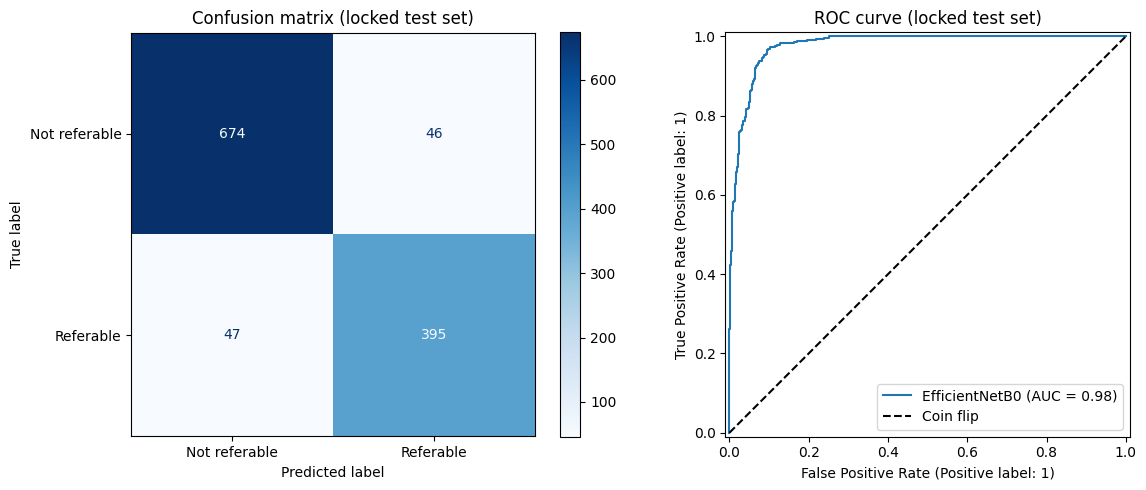

Total test images: 1162
Referable eyes correctly detected: 395
Referable eyes missed: 47
Non-referable eyes correctly cleared: 674
Non-referable eyes incorrectly flagged: 46


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

metrics = ['sensitivity', 'specificity', 'auc']
validation, testing = base_val, base_test

summary = pd.DataFrame({
    'CV validation (mean ± std)': validation[metrics].mean().round(3).astype(str) + ' ± ' + validation[metrics].std().round(3).astype(str),
    'Locked test, per fold (mean ± std)': testing[metrics].mean().round(3).astype(str) + ' ± ' + testing[metrics].std().round(3).astype(str)
})
print('Validation results per fold:')
display(validation[metrics + ['threshold']].round(3))
print('\nSummary:')
display(summary)

# 5-model ensemble with the average validation threshold
ens_prob = np.mean(base_probs, axis=0)
ens_thr = validation['threshold'].mean()
final = evaluate(y_test, ens_prob, ens_thr)
print(f"\nEnsemble on the locked test set: sensitivity = {final['sensitivity']:.3f}, "
      f"specificity = {final['specificity']:.3f}, AUC = {final['auc']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (ens_prob >= ens_thr).astype(int),
                                        display_labels=['Not referable', 'Referable'], cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion matrix (locked test set)')
RocCurveDisplay.from_predictions(y_test, ens_prob, ax=axes[1], name='EfficientNetB0')
axes[1].plot([0, 1], [0, 1], 'k--', label='Coin flip')
axes[1].set_title('ROC curve (locked test set)')
axes[1].legend()
plt.tight_layout(); plt.show()

print('Total test images:', len(y_test))
print('Referable eyes correctly detected:', final['tp'])
print('Referable eyes missed:', final['fn'])
print('Non-referable eyes correctly cleared:', final['tn'])
print('Non-referable eyes incorrectly flagged:', final['fp'])

## 7. Comparison models

**MobileNetV2** (pretrained, 2.3 million parameters) is a realistic option for the mobile app. **Simple CNN** (4 convolution blocks trained from scratch, 0.24 million parameters) is a weak baseline that shows how much transfer learning adds. All models use the same images, folds, augmentation, class weights, stopping rules and threshold method.

**BatchNorm fix for MobileNetV2.** In the first MobileNetV2 run, validation AUC in folds 1 and 2 stayed between 0.6 and 0.8 while training AUC was about 0.97, and early stopping restored the weights of epoch 1. MobileNetV2 updates its BatchNorm running averages very slowly (momentum 0.999), so validation-mode outputs lag behind training for the first epochs. The fix keeps the pretrained BatchNorm layers in inference mode, using two settings: `trainable = False` on every BatchNorm layer of the base, and calling the base with `training=False`. Convolution weights stay trainable.

### Decision rule for the main model (written before the new MobileNetV2 results were compared)
MobileNetV2 becomes the main model only if both conditions hold:
1. The paired bootstrap 95% confidence interval of (AUC of EfficientNetB0 minus AUC of MobileNetV2) includes 0 or lies entirely below 0.
2. At 90% sensitivity, the specificity of MobileNetV2 is within 3 percentage points of that of EfficientNetB0.

Otherwise EfficientNetB0 stays the main model and MobileNetV2 is documented as the smaller fallback.

In [ ]:
from tensorflow.keras import layers

def _compile(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc')])   # must be called 'auc': early stopping watches val_auc
    return model

def build_mobilenetv2(lr=1e-4):
    base = keras.applications.MobileNetV2(include_top=False, weights='imagenet',
                                          input_shape=(224, 224, 3), pooling='avg')
    for layer in base.layers:                        # keep pretrained BatchNorm statistics fixed
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    inputs = keras.Input((224, 224, 3))
    x = augment(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)    # MobileNetV2 expects values between -1 and 1
    x = base(x, training=False)                      # BatchNorm stays in inference mode
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return _compile(keras.Model(inputs, outputs), lr)

def build_simple_cnn(lr=1e-3):
    inputs = keras.Input((224, 224, 3))
    x = augment(inputs)
    x = layers.Rescaling(1 / 255)(x)
    for filters in (32, 64, 128, 128):               # 4 blocks: convolution, normalise, shrink
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return _compile(keras.Model(inputs, outputs), lr)

build_mobilenetv2().summary()
build_simple_cnn().summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 2,191,041 (8.36 MB)

 Non-trainable params: 68,224 (266.50 KB)

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,369 (946.75 KB)

 Trainable params: 241,665 (944.00 KB)

 Non-trainable params: 704 (2.75 KB)

**Check while MobileNetV2 trains (fold 1):** `val_auc` in epochs 1 to 3 should be above about 0.90 and rise together with training AUC, and `val_loss` should stay below 1. If it still collapses, set `layer.momentum = 0.9` on the BatchNorm layers of the base instead of `trainable = False` and rerun fold 1.

In [ ]:
mobilenet_val, mobilenet_test, mobilenet_probs = run_cv(build_mobilenetv2, 'mobilenetv2_bnfix', RESULTS4)
display(mobilenet_val[['fold', 'epochs_run', 'auc', 'sensitivity', 'specificity', 'threshold']].round(3))


===== mobilenetv2_bnfix: fold 1 of 5 =====
Epoch 1/20
59/59 - 28s - 478ms/step - auc: 0.8882 - loss: 0.4259 - val_auc: 0.9527 - val_loss: 0.2812 - learning_rate: 1.0000e-04
Epoch 2/20
59/59 - 8s - 135ms/step - auc: 0.9467 - loss: 0.2943 - val_auc: 0.9594 - val_loss: 0.2562 - learning_rate: 1.0000e-04
Epoch 3/20
59/59 - 8s - 136ms/step - auc: 0.9556 - loss: 0.2624 - val_auc: 0.9643 - val_loss: 0.2919 - learning_rate: 1.0000e-04
Epoch 4/20
59/59 - 8s - 137ms/step - auc: 0.9647 - loss: 0.2324 - val_auc: 0.9662 - val_loss: 0.2327 - learning_rate: 1.0000e-04
Epoch 5/20
59/59 - 8s - 137ms/step - auc: 0.9635 - loss: 0.2326 - val_auc: 0.9686 - val_loss: 0.2823 - learning_rate: 1.0000e-04
Epoch 6/20
59/59 - 9s - 145ms/step - auc: 0.9676 - loss: 0.2254 - val_auc: 0.9740 - val_loss: 0.2278 - learning_rate: 1.0000e-04
Epoch 7/20
59/59 - 8s - 136ms/step - auc: 0.9673 - loss: 0.2201 - val_auc: 0.9730 - val_loss: 0.2613 - learning_rate: 1.0000e-04
Epoch 8/20
59/59 - 8s - 139ms/step - auc: 0.9694 - l

,fold,epochs_run,auc,sensitivity,specificity,threshold
0,1,17,0.978,0.906,0.935,0.793
1,2,12,0.975,0.911,0.946,0.575
2,3,11,0.979,0.908,0.932,0.625
3,4,8,0.975,0.904,0.907,0.663
4,5,14,0.981,0.905,0.945,0.748


In [ ]:
cnn_val, cnn_test, cnn_probs = run_cv(build_simple_cnn, 'simple_cnn', RESULTS4)
display(cnn_val[['fold', 'epochs_run', 'auc', 'sensitivity', 'specificity', 'threshold']].round(3))

simple_cnn: re-scored saved models, ensemble test AUC 0.940 (earlier run reported 0.940)
simple_cnn fold 1: loaded from Drive
simple_cnn fold 2: loaded from Drive
simple_cnn fold 3: loaded from Drive
simple_cnn fold 4: loaded from Drive
simple_cnn fold 5: loaded from Drive


,fold,epochs_run,auc,sensitivity,specificity,threshold
0,1,NaN,0.910,0.900,0.826,0.607
1,2,NaN,0.899,0.905,0.833,0.406
2,3,NaN,0.943,0.903,0.857,0.301
3,4,NaN,0.931,0.904,0.834,0.605
4,5,NaN,0.912,0.915,0.844,0.662


,Model,CV val AUC,Test AUC (per fold),Ensemble sens,Ensemble spec,Ensemble AUC,Missed (FN),False alarms (FP),Params (M),Train min/fold
0,EfficientNetB0,0.975 ± 0.001,0.975 ± 0.001,0.894,0.936,0.978,47,46,4.05,NaN
1,MobileNetV2 (BN fixed),0.978 ± 0.002,0.980 ± 0.003,0.916,0.942,0.982,37,42,2.26,2.0
2,Simple CNN,0.919 ± 0.018,0.929 ± 0.012,0.919,0.835,0.940,36,119,0.24,NaN


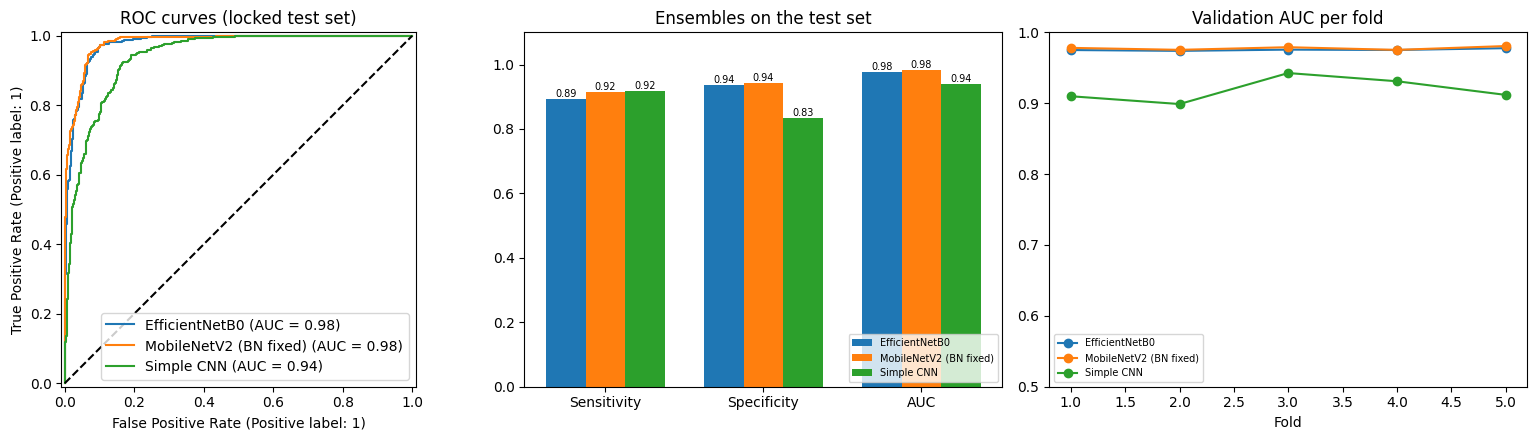

In [ ]:
def ensemble_eval(val_df, probs):
    return evaluate(y_test, np.mean(probs, axis=0), val_df['threshold'].mean())

results = {
    'EfficientNetB0':        (base_val, base_test, base_probs),
    'MobileNetV2 (BN fixed)': (mobilenet_val, mobilenet_test, mobilenet_probs),
    'Simple CNN':            (cnn_val, cnn_test, cnn_probs),
}

rows = []
for name, (val_df, test_df, probs) in results.items():
    ens = ensemble_eval(val_df, probs)
    rows.append({
        'Model': name,
        'CV val AUC': f"{val_df['auc'].mean():.3f} ± {val_df['auc'].std():.3f}",
        'Test AUC (per fold)': f"{test_df['auc'].mean():.3f} ± {test_df['auc'].std():.3f}",
        'Ensemble sens': round(ens['sensitivity'], 3), 'Ensemble spec': round(ens['specificity'], 3),
        'Ensemble AUC': round(ens['auc'], 3),
        'Missed (FN)': int(ens['fn']), 'False alarms (FP)': int(ens['fp']),
        'Params (M)': round(test_df['params'].iloc[0] / 1e6, 2),
        'Train min/fold': round(test_df['train_seconds'].mean() / 60, 1) if test_df['train_seconds'].notna().any() else None,
    })
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv(f'{RESULTS4}/model_comparison.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, (val_df, test_df, probs) in results.items():
    RocCurveDisplay.from_predictions(y_test, np.mean(probs, axis=0), ax=axes[0], name=name)
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_title('ROC curves (locked test set)')
w = 0.25
for i, name in enumerate(results):
    e = ensemble_eval(results[name][0], results[name][2])
    bars = axes[1].bar(np.arange(3) + i * w, [e['sensitivity'], e['specificity'], e['auc']], w, label=name)
    axes[1].bar_label(bars, fmt='%.2f', fontsize=7)
axes[1].set_xticks(np.arange(3) + w); axes[1].set_xticklabels(['Sensitivity', 'Specificity', 'AUC'])
axes[1].set_ylim(0, 1.1); axes[1].legend(fontsize=7, loc='lower right'); axes[1].set_title('Ensembles on the test set')
for i, name in enumerate(results):
    axes[2].plot(results[name][0]['fold'], results[name][0]['auc'], marker='o', label=name)
axes[2].set_title('Validation AUC per fold'); axes[2].set_xlabel('Fold'); axes[2].set_ylim(0.5, 1.0); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Statistical comparison and choice of the main model
Three procedures are used, all on the locked test set:
- **Bootstrap confidence intervals** for each model's AUC (2,000 resamples of the test images).
- **Paired bootstrap** for differences between two models. Both models are scored on the same resampled images, which gives an interval for the difference.
- **Matched sensitivity.** Models end up with different sensitivities at their own thresholds, so comparing overall accuracy mixes two effects. The specificity at exactly 90% sensitivity compares them on equal terms. McNemar tests are run separately on the referable eyes (a sensitivity comparison) and on the non-referable eyes (a specificity comparison). With three pairwise comparisons, the significance level is 0.05 / 3 = 0.017 (Bonferroni correction).

In [ ]:
from itertools import combinations
from sklearn.metrics import roc_curve
from statsmodels.stats.contingency_tables import mcnemar

def spec_at_sens(y_true, p, target=0.90):
    """Best specificity among ROC points that reach the target sensitivity."""
    fpr, tpr, _ = roc_curve(y_true, p)
    return 1 - fpr[tpr >= target].min()

def paired_bootstrap(y_true, p1, p2, stat, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    s1, s2 = [], []
    while len(s1) < n:
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        s1.append(stat(y_true[idx], p1[idx])); s2.append(stat(y_true[idx], p2[idx]))
    diff = np.array(s1) - np.array(s2)
    return {'m1': stat(y_true, p1), 'm2': stat(y_true, p2), 'diff': stat(y_true, p1) - stat(y_true, p2),
            'ci_low': np.percentile(diff, 2.5), 'ci_high': np.percentile(diff, 97.5),
            'ci_m1': np.percentile(s1, [2.5, 97.5]), 'ci_m2': np.percentile(s2, [2.5, 97.5])}

def mcnemar_split(y_true, pred1, pred2):
    out = {}
    for label, text in ((1, 'referable eyes (sensitivity)'), (0, 'non-referable eyes (specificity)')):
        m = y_true == label
        c1, c2 = pred1[m] == y_true[m], pred2[m] == y_true[m]
        table = [[np.sum(c1 & c2), np.sum(c1 & ~c2)], [np.sum(~c1 & c2), np.sum(~c1 & ~c2)]]
        out[text] = (int(table[0][1]), int(table[1][0]), mcnemar(table, exact=True).pvalue)
    return out

ens_p = {n: np.mean(r[2], axis=0) for n, r in results.items()}
ens_t = {n: r[0]['threshold'].mean() for n, r in results.items()}
alpha = 0.05 / 3

print('AUC with bootstrap 95% CI')
for n, p in ens_p.items():
    b = paired_bootstrap(y_test, p, p, roc_auc_score)
    print(f"  {n:24s} {b['m1']:.3f}  [{b['ci_m1'][0]:.3f}, {b['ci_m1'][1]:.3f}]")

for a, b_ in combinations(results, 2):
    print(f'\n{a}  vs  {b_}')
    auc_c = paired_bootstrap(y_test, ens_p[a], ens_p[b_], roc_auc_score)
    spec_c = paired_bootstrap(y_test, ens_p[a], ens_p[b_], spec_at_sens)
    print(f"  AUC difference {auc_c['diff']:+.4f}, paired 95% CI [{auc_c['ci_low']:+.4f}, {auc_c['ci_high']:+.4f}]")
    print(f"  Specificity at 90% sensitivity: {spec_c['m1']:.3f} vs {spec_c['m2']:.3f}, difference {spec_c['diff']:+.3f}, 95% CI [{spec_c['ci_low']:+.3f}, {spec_c['ci_high']:+.3f}]")
    res = mcnemar_split(y_test, (ens_p[a] >= ens_t[a]).astype(int), (ens_p[b_] >= ens_t[b_]).astype(int))
    for text, (only1, only2, pval) in res.items():
        print(f"  McNemar, {text}: only first right {only1}, only second right {only2}, p = {pval:.4f} "
              f"({'significant' if pval < alpha else 'not significant'} at {alpha:.3f})")

# ---- decision rule from section 7: EfficientNetB0 (a) vs MobileNetV2 (b) ----
a, b_ = 'EfficientNetB0', 'MobileNetV2 (BN fixed)'
auc_c = paired_bootstrap(y_test, ens_p[a], ens_p[b_], roc_auc_score)
spec_c = paired_bootstrap(y_test, ens_p[a], ens_p[b_], spec_at_sens)
rule_1 = auc_c['ci_low'] <= 0
rule_2 = spec_c['diff'] <= 0.03
MAIN = 'mobilenetv2_bnfix' if (rule_1 and rule_2) else 'effb0'
print('\nRule 1 (AUC gap interval includes 0 or favours MobileNetV2):', rule_1)
print('Rule 2 (MobileNetV2 specificity at 90% sensitivity within 3 points):', rule_2)
print('MAIN MODEL:', 'MobileNetV2' if MAIN == 'mobilenetv2_bnfix' else 'EfficientNetB0')

AUC with bootstrap 95% CI
  EfficientNetB0           0.978  [0.971, 0.984]
  MobileNetV2 (BN fixed)   0.982  [0.975, 0.987]
  Simple CNN               0.940  [0.927, 0.952]

EfficientNetB0  vs  MobileNetV2 (BN fixed)
  AUC difference -0.0036, paired 95% CI [-0.0069, -0.0006]
  Specificity at 90% sensitivity: 0.936 vs 0.942, difference -0.006, 95% CI [-0.017, +0.007]
  McNemar, referable eyes (sensitivity): only first right 8, only second right 18, p = 0.0755 (not significant at 0.017)
  McNemar, non-referable eyes (specificity): only first right 5, only second right 9, p = 0.4240 (not significant at 0.017)

EfficientNetB0  vs  Simple CNN
  AUC difference +0.0378, paired 95% CI [+0.0270, +0.0492]
  Specificity at 90% sensitivity: 0.936 vs 0.846, difference +0.090, 95% CI [+0.068, +0.122]
  McNemar, referable eyes (sensitivity): only first right 29, only second right 40, p = 0.2284 (not significant at 0.017)
  McNemar, non-referable eyes (specificity): only first right 78, only second ri

## 9. The single model for the app
A phone runs one network, not an average of five. The fold model with the **median validation AUC** of the main architecture is used. It is never selected by test results. Its own validation threshold is used, because thresholds differ a lot between folds. Its test performance, with bootstrap confidence intervals, is the performance to report for the app.

In [ ]:
from sklearn.metrics import confusion_matrix

if MAIN == 'effb0':
    val_df, model_dir, prefix = base_val, SAVE_DIR, 'effb0'
else:
    val_df, model_dir, prefix = mobilenet_val, RESULTS4, 'mobilenetv2_bnfix'

order = np.argsort(val_df['auc'].values)
pick = int(order[len(order) // 2])                 # median-AUC fold, 0-based position
fold = pick + 1
thr = float(val_df['threshold'].iloc[pick])
model_path = f'{model_dir}/{prefix}_fold{fold}.keras'
print(f'{prefix}: median-AUC fold = {fold}, validation AUC = {val_df["auc"].iloc[pick]:.3f}, threshold = {thr:.3f}')

final_model = keras.models.load_model(model_path)
p_test = final_model.predict(X_test.astype('float32'), verbose=0).ravel()
single = evaluate(y_test, p_test, thr)
print(f"Test: sensitivity {single['sensitivity']:.3f}, specificity {single['specificity']:.3f}, AUC {single['auc']:.3f}")
print(f"Referable eyes missed {single['fn']} of {single['tp'] + single['fn']}, false alarms {single['fp']} of {single['tn'] + single['fp']} non-referable eyes")

rng = np.random.default_rng(42)
sens_b, spec_b, auc_b = [], [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    yt, pr = y_test[idx], p_test[idx]
    if len(np.unique(yt)) < 2:
        continue
    tn, fp, fn, tp = confusion_matrix(yt, (pr >= thr).astype(int), labels=[0, 1]).ravel()
    sens_b.append(tp / (tp + fn)); spec_b.append(tn / (tn + fp)); auc_b.append(roc_auc_score(yt, pr))
for label, vals in (('Sensitivity', sens_b), ('Specificity', spec_b), ('AUC', auc_b)):
    lo, hi = np.percentile(vals, [2.5, 97.5])
    print(f'{label} 95% CI: [{lo:.3f}, {hi:.3f}]')

OUT = os.path.join(DATA_DIR, 'app_export')
os.makedirs(OUT, exist_ok=True)
json.dump({'model': prefix, 'fold': fold, 'threshold': thr}, open(os.path.join(OUT, 'threshold.json'), 'w'))

mobilenetv2_bnfix: median-AUC fold = 1, validation AUC = 0.978, threshold = 0.793
Test: sensitivity 0.905, specificity 0.943, AUC 0.982
Referable eyes missed 42 of 442, false alarms 41 of 720 non-referable eyes
Sensitivity 95% CI: [0.878, 0.931]
Specificity 95% CI: [0.925, 0.960]
AUC 95% CI: [0.976, 0.988]


### Results by DR grade

The same model and threshold, broken down by the clinicians' original grade. Computed in `app_validation.ipynb` (per-grade cell), which reproduces the figures above exactly (sensitivity 0.905, specificity 0.943, AUC 0.982). Intervals are Wilson 95% intervals.

| Grade | Test images | Measure | Count | Rate | 95% CI |
| --- | --- | --- | --- | --- | --- |
| 0 No DR | 606 | correctly not flagged | 606 | 1.000 | 0.994 to 1.000 |
| 1 Mild | 114 | correctly not flagged | 73 | 0.640 | 0.549 to 0.723 |
| 2 Moderate | 292 | flagged | 260 | 0.890 | 0.849 to 0.921 |
| 3 Severe | 52 | flagged | 51 | 0.981 | 0.899 to 0.997 |
| 4 Proliferative | 98 | flagged | 89 | 0.908 | 0.835 to 0.951 |

**Reading the table.** Every false alarm (41) is a grade 1 eye: no eye without DR was flagged. Most misses (32 of 42) are grade 2, the borderline between referable and not, where human graders also disagree most. Ten missed eyes are severe or proliferative (1 and 9); these are the costliest errors, and the small grade 3 and 4 counts make their rates imprecise. The majority-class baseline, which flags nothing, reaches an accuracy of 0.620 with a sensitivity of 0.

## 10. Explainability: class activation maps
**What a map shows.** A class activation map (CAM) marks the image regions that contributed most to the referable score. It shows where the model found evidence. It is not a diagnosis and it does not show that the model is right.

**Method.** The network ends with global average pooling followed by one Dense layer. For such a network the referral logit equals `w · mean(feature map) + b`, so the map is the last feature map weighted by the Dense weights `w`. This is exact and needs no gradients. For MobileNetV2 the rescaling layer sits outside the pretrained base, so the same rescaling is applied by hand before the base. EfficientNetB0 normalises inside the base and takes raw 0 to 255 pixels.

**Three groups of images**, each sampled with a fixed random seed (no hand-picking):
- **A.** The 38 groups of conflicting-label duplicates that were removed from training (30 exact plus 8 near-duplicate groups). The model never saw these. Maps and probabilities help a clinician audit whether the model's attention and the conflicting labels make sense.
- **B.** Referable test eyes the model missed.
- **C.** Referable test eyes the model caught.

In [ ]:
def find_base(model):
    """The pretrained sub-network: the largest layer that is itself a model (the augment block is a small one)."""
    return max((l for l in model.layers if isinstance(l, keras.Model)), key=lambda l: len(l.layers))

def last_feature_layer(base):
    names = [l.name for l in base.layers]
    for candidate in ('top_activation', 'out_relu'):        # EfficientNetB0, MobileNetV2
        if candidate in names:
            return candidate
    raise ValueError('Set the name of the last convolutional activation by hand')

def make_cam(model, img_rgb, mobilenet_style=False):
    """img_rgb: 224x224x3 uint8 from preprocess_image. Returns the map resized to 224x224 and the probability."""
    base = find_base(model)
    feat_model = keras.Model(base.inputs, base.get_layer(last_feature_layer(base)).output)
    x = img_rgb.astype('float32')[None]
    prob = float(model.predict(x, verbose=0)[0, 0])
    if mobilenet_style:
        x = x / 127.5 - 1.0                                   # the rescaling layer that sits outside the base
    fmap = feat_model(x, training=False).numpy()[0]          # 7 x 7 x 1280
    w = model.layers[-1].get_weights()[0][:, 0]              # Dense kernel, one weight per channel
    cam = np.maximum(fmap @ w, 0)
    cam = cam / (cam.max() + 1e-10)
    return cv2.resize(cam, (224, 224)), prob

def overlay(img_rgb, cam, alpha=0.4):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.clip(heat * alpha + img_rgb * (1 - alpha), 0, 255).astype(np.uint8)

is_mobilenet = (MAIN != 'effb0')
rng = np.random.default_rng(42)

# Group A: all 38 conflicting-label groups in the raw table, one image per group
df = set_image_paths(df)
conflict = df.groupby('phash').filter(lambda g: g['diagnosis'].nunique() > 1)
by_group = conflict.groupby('phash')
print('Conflicting-label groups:', by_group.ngroups)                 # expect 38
labels_in_group = by_group['diagnosis'].apply(lambda s: sorted(set(s)))
firsts = by_group.head(1)
sel_a = firsts.iloc[rng.choice(len(firsts), size=6, replace=False)]
cohort_a = [(r.image_path, r.id_code, f'labels in group: {labels_in_group[r.phash]}') for r in sel_a.itertuples()]

# Groups B and C: referable test eyes missed and caught
test_df = set_image_paths(df_cleaned[df_cleaned['split'] == 'test'].reset_index(drop=True).copy())
test_df['prob'] = p_test
missed = test_df[(test_df['referable'] == 1) & (test_df['prob'] < thr)]
caught = test_df[(test_df['referable'] == 1) & (test_df['prob'] >= thr)]
sel_b = missed.iloc[rng.choice(len(missed), size=min(6, len(missed)), replace=False)]
sel_c = caught.iloc[rng.choice(len(caught), size=min(6, len(caught)), replace=False)]
cohort_b = [(r.image_path, r.id_code, f'true grade {r.diagnosis}, missed') for r in sel_b.itertuples()]
cohort_c = [(r.image_path, r.id_code, f'true grade {r.diagnosis}, caught') for r in sel_c.itertuples()]

for name, items in {'A_conflicting_removed': cohort_a, 'B_missed_referable': cohort_b, 'C_caught_referable': cohort_c}.items():
    if not items:
        print(f'{name}: no images in this group'); continue
    fig, axes = plt.subplots(2, len(items), figsize=(3 * len(items), 6.4), squeeze=False)
    for j, (path_, idc, note) in enumerate(items):
        img = preprocess_image(path_, target_size=224)
        cam, prob = make_cam(final_model, img, mobilenet_style=is_mobilenet)
        axes[0, j].imshow(img); axes[0, j].axis('off'); axes[0, j].set_title(f'{idc[:8]}\n{note}', fontsize=8)
        axes[1, j].imshow(overlay(img, cam)); axes[1, j].axis('off'); axes[1, j].set_title(f'p(referable) = {prob:.2f}', fontsize=8)
    fig.suptitle(f'Class activation maps: {name.replace("_", " ")}', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(DATA_DIR, f'cam_{name}.png'), dpi=150, bbox_inches='tight')
    plt.show()

Conflicting-label groups: 38


[Figures removed from the repository copy: they show class activation maps over test and removed images. They are APTOS 2019
photographs, which the competition rules do not allow us to redistribute. Run this cell
with the dataset in place to see them.]


### Sanity check of the maps
A copy of the network with randomly initialised weights should produce unrelated maps. If the maps of the trained and the random network look alike, the picture shows image structure and not what the model learned. The correlation between them should be low.

In [ ]:
random_model = keras.models.clone_model(final_model)        # same architecture, fresh random weights
corrs = []
for r in caught.iloc[:6].itertuples():
    img = preprocess_image(r.image_path, target_size=224)
    real, _ = make_cam(final_model, img, mobilenet_style=is_mobilenet)
    rand, _ = make_cam(random_model, img, mobilenet_style=is_mobilenet)
    corrs.append(np.corrcoef(real.ravel(), rand.ravel())[0, 1])
print('Correlation between trained and random-weight maps (low is good):', np.round(corrs, 2))

Correlation between trained and random-weight maps (low is good): [ 0.23 -0.03  0.27 -0.45  0.14 -0.35]


## 11. Export to TensorFlow Lite and check against the Keras model
The chosen network is converted to TensorFlow Lite with dynamic-range quantisation (weights stored as 8-bit integers), which makes the file smaller and faster on a phone. Quantisation can change probabilities slightly, so the converted model is run on all test images and compared with the Keras model. The check passes when the AUC differs by at most 0.005 and at least 99% of referral decisions are identical at the chosen threshold.

In [ ]:
def make_inference_model(model):
    """Same trained weights without the training-only layers (augmentation, dropout), which TFLite cannot run."""
    base = find_base(model)
    inputs = keras.Input((224, 224, 3))
    x = inputs
    for l in model.layers:
        if isinstance(l, layers.Rescaling):               # top-level rescaling (MobileNetV2 and the simple CNN)
            x = l(x)
    x = base(x, training=False)
    return keras.Model(inputs, model.layers[-1](x))

inference_model = make_inference_model(final_model)
check = inference_model.predict(X_test[:20].astype('float32'), verbose=0).ravel()
assert np.allclose(check, p_test[:20], atol=1e-4), 'inference copy differs from the trained model'
print('Inference copy matches the trained model on 20 test images.')

export_dir = os.path.join(OUT, 'saved_model')
inference_model.export(export_dir)
converter = tf.lite.TFLiteConverter.from_saved_model(export_dir)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_bytes = converter.convert()

tflite_path = os.path.join(OUT, f'dr_triage_{prefix}.tflite')
with open(tflite_path, 'wb') as f:
    f.write(tflite_bytes)
print('TFLite size (MB):', round(len(tflite_bytes) / 1e6, 2))

interp = tf.lite.Interpreter(model_content=tflite_bytes)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
print('Input:', inp['shape'], inp['dtype'], '| Output:', out['shape'], out['dtype'])

p_tflite = np.empty(len(X_test), dtype='float32')
for i, im in enumerate(tqdm(X_test)):
    interp.set_tensor(inp['index'], im[None].astype('float32'))
    interp.invoke()
    p_tflite[i] = interp.get_tensor(out['index'])[0, 0]

auc_keras, auc_tfl = roc_auc_score(y_test, p_test), roc_auc_score(y_test, p_tflite)
agree = np.mean((p_test >= thr) == (p_tflite >= thr))
tfl = evaluate(y_test, p_tflite, thr)
print(f'AUC Keras {auc_keras:.4f} | TFLite {auc_tfl:.4f} | difference {abs(auc_keras - auc_tfl):.4f}')
print(f'Referral decisions identical on {agree * 100:.2f}% of test images; largest probability difference {np.max(np.abs(p_test - p_tflite)):.3f}')
print(f"TFLite on the test set: sensitivity {tfl['sensitivity']:.3f}, specificity {tfl['specificity']:.3f}")
PARITY_OK = abs(auc_keras - auc_tfl) <= 0.005 and agree >= 0.99
print('PARITY PASS' if PARITY_OK else 'PARITY FAIL: convert again with float16 quantisation or without quantisation')

Inference copy matches the trained model on 20 test images.
Saved artifact at '/content/drive/MyDrive/APTOS2019_Data/app_export/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_715')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133844642985552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844642987664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844642987472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844642987856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844642986896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844642987088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844571996432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844571996624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133844642987280: TensorSpec(shape=(), dtype=tf

  0%|          | 0/1162 [00:00<?, ?it/s]

AUC Keras 0.9822 | TFLite 0.9823 | difference 0.0000
Referral decisions identical on 99.31% of test images; largest probability difference 0.082
TFLite on the test set: sensitivity 0.894, specificity 0.944
PARITY PASS


In [ ]:
spec = {
    'model_file': os.path.basename(tflite_path),
    'input': {'shape': [1, 224, 224, 3], 'dtype': 'float32', 'channels': 'RGB', 'range': '0-255 raw values, no normalisation'},
    'preprocessing': [
        'decode the image to RGB',
        'convert a copy to grey; keep the rows and columns that contain any pixel above 7; crop to them (keep the original if nothing remains)',
        'resize to 224x224 with bilinear interpolation (aspect ratio is not preserved)'],
    'output': 'one float: probability that the eye is referable (grade 2 or higher)',
    'decision': f'refer if probability >= {thr:.4f}',
    'validated_on': 'APTOS 2019 (India). Not tested on smartphone photographs or on Kenyan patients.',
}
json.dump(spec, open(os.path.join(OUT, 'preprocessing_spec.json'), 'w'), indent=2)
print(json.dumps(spec, indent=2))
print('\nFiles for the app are in:', OUT)
# To download from Colab:  from google.colab import files; files.download(tflite_path)

{
  "model_file": "dr_triage_mobilenetv2_bnfix.tflite",
  "input": {
    "shape": [
      1,
      224,
      224,
      3
    ],
    "dtype": "float32",
    "channels": "RGB",
    "range": "0-255 raw values, no normalisation"
  },
  "preprocessing": [
    "decode the image to RGB",
    "convert a copy to grey; keep the rows and columns that contain any pixel above 7; crop to them (keep the original if nothing remains)",
    "resize to 224x224 with bilinear interpolation (aspect ratio is not preserved)"
  ],
  "output": "one float: probability that the eye is referable (grade 2 or higher)",
  "decision": "refer if probability >= 0.7931",
  "validated_on": "APTOS 2019 (India). Not tested on smartphone photographs or on Kenyan patients."
}

Files for the app are in: /content/drive/MyDrive/APTOS2019_Data/app_export


## 12. Summary of results
The next cell prints the results of this run from the variables above, so the numbers always match the outputs.

In [ ]:
n_total = len(df_cleaned)
print(f'DATA   {len(df)} raw images -> {n_total} after cleaning ({int(y.sum())} referable, {int((1 - y).sum())} non-referable)')
print(f'SPLIT  development {len(y_dev)} images, locked test {len(y_test)} images ({len(y_test) / n_total:.1%}), 5-fold cross-validation, grouped by pHash')
print('\nMODEL COMPARISON (5-model ensembles on the locked test set)')
display(comparison)
print(f"\nMAIN MODEL  {'MobileNetV2' if MAIN == 'mobilenetv2_bnfix' else 'EfficientNetB0'}  (chosen by the rule in section 7)")
print(f"SINGLE MODEL FOR THE APP  {prefix}, fold {fold}, threshold {thr:.3f}")
print(f"  sensitivity {single['sensitivity']:.3f}  specificity {single['specificity']:.3f}  AUC {single['auc']:.3f}")
print(f"  missed {single['fn']} of {single['tp'] + single['fn']} referable eyes; {single['fp']} false alarms among {single['tn'] + single['fp']} non-referable eyes")
print(f"  TFLite size {len(tflite_bytes) / 1e6:.1f} MB; {'parity with Keras confirmed' if PARITY_OK else 'PARITY CHECK FAILED'}")

DATA   3662 raw images -> 3487 after cleaning (1354 referable, 2133 non-referable)
SPLIT  development 2325 images, locked test 1162 images (33.3%), 5-fold cross-validation, grouped by pHash

MODEL COMPARISON (5-model ensembles on the locked test set)


,Model,CV val AUC,Test AUC (per fold),Ensemble sens,Ensemble spec,Ensemble AUC,Missed (FN),False alarms (FP),Params (M),Train min/fold
0,EfficientNetB0,0.975 ± 0.001,0.975 ± 0.001,0.894,0.936,0.978,47,46,4.05,NaN
1,MobileNetV2 (BN fixed),0.978 ± 0.002,0.980 ± 0.003,0.916,0.942,0.982,37,42,2.26,2.0
2,Simple CNN,0.919 ± 0.018,0.929 ± 0.012,0.919,0.835,0.940,36,119,0.24,NaN



MAIN MODEL  MobileNetV2  (chosen by the rule in section 7)
SINGLE MODEL FOR THE APP  mobilenetv2_bnfix, fold 1, threshold 0.793
  sensitivity 0.905  specificity 0.943  AUC 0.982
  missed 42 of 442 referable eyes; 41 false alarms among 720 non-referable eyes
  TFLite size 2.5 MB; parity with Keras confirmed


### Limitations
- **Data source.** All images come from one dataset collected in India. Performance on smartphone photographs, other cameras and Kenyan patients is unknown and must be tested before any clinical use.
- **No patient identifiers.** APTOS has no patient ID, so two images of the same patient cannot be linked. The pHash grouping removes duplicated photographs, not necessarily the same eye photographed twice.
- **Duplicate detection.** Groups are formed from identical pHash values. Near-duplicates whose hashes differ slightly would not be grouped.
- **Label noise.** 38 groups of near-identical photographs carry conflicting grades, which shows that some labels are uncertain. Cleaning removed those groups.
- **Preprocessing.** Resizing to 224x224 does not keep the aspect ratio and reduces fine detail such as small haemorrhages.
- **Threshold.** The decision threshold is chosen on validation data for 90% sensitivity. Test sensitivity differs slightly from 90%, and the 95% intervals above show how much.
- **Explainability.** Class activation maps show where the model found evidence. They do not validate the prediction, and any clinical use needs review by an ophthalmologist.
- **Triage only.** The model supports referral decisions. It does not diagnose.

## 13. Deployment

The app's model runs on a server. Section 11 showed that the TensorFlow Lite export agrees with the Keras model on 99.3% of test decisions but lowers sensitivity from 0.905 to 0.894, so the full Keras model is served and the phone sends photographs to it.

| Part | Folder in the [app repository](https://github.com/JeremiahSents/sentient_research) | Role |
| --- | --- | --- |
| Model service | `apps/model-service` | Python (FastAPI). Repeats the preprocessing of section 5 (crop where greyscale > 7, resize to 224 x 224, RGB, raw 0 to 255 values), checks image quality, runs `model/model.keras` (the fold-1 MobileNetV2 from section 9) and compares the probability with the threshold 0.793. |
| API | `apps/api` | Node (Express) with PostgreSQL. Stores patients, screenings, photographs, results and referrals, and calls the model service. |
| Android app | `apps/mobile` | Kotlin and Jetpack Compose. Intake, photo selection, and the result with a "How this result was made" panel. |

**Checks that the server matches this notebook.**
- **Parity.** 20 images were scored by this notebook's code and by the server. The largest probability difference was 0.0000015 and no referral decision changed (`scripts/parity_check.py` in the model service).
- **Image quality.** The server marks a photograph ungradable, and sends it to a specialist, when its retina size, coverage, brightness or sharpness falls outside the range of the 2,325 development images (1st to 99th percentile, `model/quality.json` in the model service). The server also rejects photographs whose colours fall outside the range of real fundus photographs, such as a scanned document; colour alone cannot catch every ordinary photograph.
- **Explanation.** The server computes the same class activation map as section 10 and shows it on the phone only when the map rebuilds the model's probability to within 0.001.

**Models.** The base model, EfficientNetB0 fold 1 (section 6), is `models/effb0_fold1.keras` in this repository: the same fold as the app model, so both were trained and validated on identical images. The app model, MobileNetV2 fold 1, is `apps/model-service/model/model.keras` in the [app repository](https://github.com/JeremiahSents/sentient_research), with its threshold in `threshold.json`.

**Before clinical use.** These results come from one Indian dataset. The model must be validated on photographs from Kenyan clinics and cameras, and the referral threshold and queue rules need sign-off by an ophthalmologist.